In [1]:
from typing import TypedDict
import random

class State(TypedDict):
    input_number: int
    result_number: int
    random_number: int
    next_node: str 

In [2]:
def add(state: State) -> State:
    state["result_number"] = state["input_number"] + state["random_number"]
    return state

def sub(state: State) -> State:
    if state["random_number"] > state["input_number"] :
        state["result_number"] = state["random_number"] - state["input_number"]
    else:
        state["result_number"] = state["input_number"] - state["random_number"]
    return state

def div(state: State) -> State:
    state["result_number"] = state["input_number"] // state["random_number"]
    return state

def randomize(state: State) -> State:
    state["random_number"] = random.randint(1, 10)
    return state

def thinker(state: State) -> State:
    print(state)
    # 8 - 10
    if state["random_number"] > 8:
        state["next_node"] = "add"
    # 6 - 7
    elif state["random_number"] < 8 and state["random_number"] > 5:
        state["next_node"] = "sub"
    # 1 - 5 
    else:
        state["next_node"] = "div"
    return state



In [3]:
my_state: State = {
    "random_number": 0,
    "input_number": 15,
    "result_number": 0,
    "next_node": "",
}

# # populate the random_number in the state
# randomize(my_state)

# add(my_state)
# print(my_state)

# sub(my_state)
# print(my_state)

# div(my_state)
# print(my_state)

In [4]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(State)

builder.add_node("add", add)
builder.add_node("sub", sub)
builder.add_node("div", div)
builder.add_node("thinker_node", thinker)
builder.add_node("randomize", randomize)

builder.add_edge(START, "randomize")
builder.add_edge("randomize", "thinker_node")

builder.add_conditional_edges("thinker_node", lambda state: state["next_node"], ["add", "sub", "div"])

builder.add_edge("add", END)
builder.add_edge("sub", END)
builder.add_edge("div", END)

# tools.

graph = builder.compile()


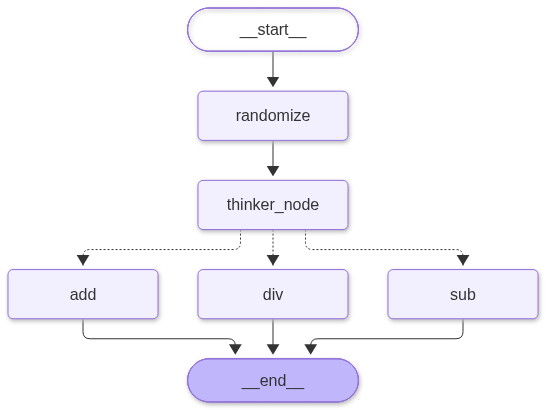

In [5]:

from IPython.display import display, Image
display(Image(graph.get_graph().draw_mermaid_png()))


In [10]:
# randomize(my_state)
graph.invoke(my_state)

{'input_number': 15, 'result_number': 0, 'random_number': 4, 'next_node': ''}


{'input_number': 15,
 'result_number': 3,
 'random_number': 4,
 'next_node': 'div'}